In [ ]:
# Step 1: Mount Drive fresh
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
print("Drive mounted!")

Mounted at /content/drive
Drive mounted!


In [ ]:
import numpy as np
import os
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from scipy import signal as scipy_signal
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Check GPU
print(f"PyTorch version: {torch.__version__}")
print(f"GPU available:   {torch.cuda.is_available()}")
if torch.cuda.is_available():
    print(f"GPU name:        {torch.cuda.get_device_name(0)}")
    print(f"GPU memory:      {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"\nUsing device: {device}")

# Dataset path
DATASET_PATH = '/content/drive/MyDrive/RF_Project/KRI-16Devices-RawData'

PyTorch version: 2.10.0+cu128
GPU available:   True
GPU name:        Tesla T4
GPU memory:      15.6 GB

Using device: cuda


In [ ]:
# ── Explore entire dataset ────────────────────────────────────────────────────
all_distances = sorted(os.listdir(DATASET_PATH))
print(f"All distance folders: {all_distances}")
print(f"Total folders: {len(all_distances)}\n")

# Count files per folder
total_files = 0
device_ids_global = set()

for dist in all_distances:
    dist_path = os.path.join(DATASET_PATH, dist)
    if not os.path.isdir(dist_path):
        continue
    files = [f for f in os.listdir(dist_path) if f.endswith('.sigmf-data')]
    total_files += len(files)
    for f in files:
        device_ids_global.add(f.split('_')[3])
    print(f"  {dist:6s} → {len(files):2d} .sigmf-data files")

device_ids_global = sorted(list(device_ids_global))
device_to_label   = {d: i for i, d in enumerate(device_ids_global)}

print(f"\nTotal .sigmf-data files across all folders: {total_files}")
print(f"Total unique devices: {len(device_ids_global)}")
print(f"\nDevice ID → Label mapping:")
for dev, lbl in device_to_label.items():
    print(f"  {dev} → class {lbl}")

All distance folders: ['14ft', '20ft', '26ft', '2ft', '32ft', '38ft', '44ft', '50ft', '56ft', '62ft', '8ft']
Total folders: 11

  14ft   → 32 .sigmf-data files
  20ft   → 32 .sigmf-data files
  26ft   → 32 .sigmf-data files
  2ft    → 32 .sigmf-data files
  32ft   → 32 .sigmf-data files
  38ft   → 32 .sigmf-data files
  44ft   → 32 .sigmf-data files
  50ft   → 32 .sigmf-data files
  56ft   → 32 .sigmf-data files
  62ft   → 32 .sigmf-data files
  8ft    → 32 .sigmf-data files

Total .sigmf-data files across all folders: 352
Total unique devices: 16

Device ID → Label mapping:
  3123D52 → class 0
  3123D54 → class 1
  3123D58 → class 2
  3123D64 → class 3
  3123D65 → class 4
  3123D70 → class 5
  3123D76 → class 6
  3123D78 → class 7
  3123D79 → class 8
  3123D7B → class 9
  3123D7D → class 10
  3123D7E → class 11
  3123D80 → class 12
  3123D89 → class 13
  3123EFE → class 14
  3124E4A → class 15


In [ ]:
# ── Configuration ─────────────────────────────────────────────────────────────
# We use these distances for training
# 2ft, 8ft, 14ft, 20ft, 26ft → training distances (close to medium)
# 62ft                        → held out for cross-distance test (your novel experiment)

TRAIN_DISTANCES  = ['2ft', '8ft', '14ft', '20ft', '26ft']
TEST_DISTANCE    = '62ft'   # held out completely for generalization test
CHUNKS_PER_FILE  = 50       # 50 chunks per file → more samples
SAMPLES_PER_CHUNK = 4096    # IQ samples per chunk (gives clean spectrogram)
SEQ_LEN_LSTM     = 256      # sequence length for LSTM (shorter = better gradient flow)

print(f"Training distances:  {TRAIN_DISTANCES}")
print(f"Test distance:       {TEST_DISTANCE}")
print(f"Chunks per file:     {CHUNKS_PER_FILE}")
print(f"Samples per chunk:   {SAMPLES_PER_CHUNK}")
print()

# ── Helper: normalize a single IQ array ───────────────────────────────────────
def normalize_iq(iq):
    """Normalize IQ to zero mean and unit std — critical for LSTM."""
    i_norm = (iq.real - iq.real.mean()) / (iq.real.std() + 1e-8)
    q_norm = (iq.imag - iq.imag.mean()) / (iq.imag.std() + 1e-8)
    return i_norm + 1j * q_norm

# ── Helper: IQ chunk → spectrogram (for CNN) ──────────────────────────────────
def iq_to_spectrogram(iq_chunk):
    """Convert IQ chunk to normalized log-power spectrogram."""
    _, _, Sxx = scipy_signal.spectrogram(
        iq_chunk,
        fs=5e6,
        nperseg=128,
        noverlap=64,
        nfft=256,
        return_onesided=False
    )
    Sxx_db = 10 * np.log10(np.abs(Sxx) + 1e-10)
    # Normalize to [-1, 1]
    Sxx_mean = Sxx_db.mean()
    Sxx_std  = Sxx_db.std() + 1e-8
    return ((Sxx_db - Sxx_mean) / Sxx_std).astype(np.float32)

# ── Main loader: loads both CNN and LSTM data together ────────────────────────
def load_all_data(dataset_path, distances, chunks_per_file=50,
                  samples_per_chunk=4096, seq_len=256, verbose=True):
    """
    Load data from multiple distance folders.
    Returns:
        X_cnn  : (N, 256, T) spectrograms for CNN
        X_lstm : (N, seq_len, 2) IQ sequences for LSTM
        y      : (N,) labels
        device_ids: list of device IDs
    """
    device_ids_set = set()
    for dist in distances:
        dp = os.path.join(dataset_path, dist)
        if not os.path.isdir(dp):
            continue
        for f in os.listdir(dp):
            if f.endswith('.sigmf-data'):
                device_ids_set.add(f.split('_')[3])

    device_ids_lst = sorted(list(device_ids_set))
    dev_to_lbl     = {d: i for i, d in enumerate(device_ids_lst)}

    X_cnn, X_lstm, y_all = [], [], []

    for dist in distances:
        dist_path = os.path.join(dataset_path, dist)
        if not os.path.isdir(dist_path):
            continue

        files = sorted([f for f in os.listdir(dist_path)
                        if f.endswith('.sigmf-data')])

        if verbose:
            print(f"\n── Loading {dist} ({len(files)} files) ──")

        for filename in files:
            dev_id   = filename.split('_')[3]
            label    = dev_to_lbl[dev_id]
            filepath = os.path.join(dist_path, filename)

            raw_iq = np.fromfile(filepath, dtype=np.complex128)

            # Normalize entire file first
            raw_iq_norm = normalize_iq(raw_iq)

            cnn_count = 0
            for i in range(chunks_per_file):
                start = i * samples_per_chunk
                end   = start + samples_per_chunk
                if end > len(raw_iq_norm):
                    break

                chunk = raw_iq_norm[start:end]

                # ── CNN: spectrogram ─────────────────────────────
                spec = iq_to_spectrogram(chunk)
                X_cnn.append(spec)

                # ── LSTM: short IQ subsequence ───────────────────
                # Take first seq_len samples from the chunk
                iq_sub = chunk[:seq_len]
                iq_2d  = np.stack([iq_sub.real,
                                   iq_sub.imag], axis=1).astype(np.float32)
                X_lstm.append(iq_2d)

                y_all.append(label)
                cnn_count += 1

            if verbose:
                print(f"   {filename[:45]:45s} label={label}  chunks={cnn_count}")

    X_cnn  = np.array(X_cnn)    # (N, 256, T)
    X_lstm = np.array(X_lstm)   # (N, seq_len, 2)
    y_all  = np.array(y_all)    # (N,)

    print(f"\n{'='*60}")
    print(f"Distances loaded:  {distances}")
    print(f"Total samples:     {len(y_all)}")
    print(f"CNN X shape:       {X_cnn.shape}")
    print(f"LSTM X shape:      {X_lstm.shape}")
    print(f"Labels shape:      {y_all.shape}")
    print(f"Samples per class: {len(y_all) // len(device_ids_lst)}")
    print(f"{'='*60}")

    return X_cnn, X_lstm, y_all, device_ids_lst

# ── Load training data (multiple distances) ────────────────────────────────────
print("Loading training data from multiple distances...")
print("This will take a few minutes — reading from Google Drive...\n")

X_cnn_all, X_lstm_all, y_all, device_ids = load_all_data(
    DATASET_PATH,
    distances    = TRAIN_DISTANCES,
    chunks_per_file  = CHUNKS_PER_FILE,
    samples_per_chunk= SAMPLES_PER_CHUNK,
    seq_len      = SEQ_LEN_LSTM,
    verbose      = True
)

NUM_CLASSES = len(device_ids)
print(f"\nNumber of classes: {NUM_CLASSES}")
print(f"Device IDs: {device_ids}")

# Class distribution check
print("\nSamples per class:")
for i, dev in enumerate(device_ids):
    count = np.sum(y_all == i)
    print(f"  Class {i:2d} ({dev}): {count} samples")

Training distances:  ['2ft', '8ft', '14ft', '20ft', '26ft']
Test distance:       62ft
Chunks per file:     50
Samples per chunk:   4096

Loading training data from multiple distances...
This will take a few minutes — reading from Google Drive...


── Loading 2ft (32 files) ──
   WiFi_air_X310_3123D52_2ft_run1.sigmf-data     label=0  chunks=50
   WiFi_air_X310_3123D52_2ft_run2.sigmf-data     label=0  chunks=50
   WiFi_air_X310_3123D54_2ft_run1.sigmf-data     label=1  chunks=50
   WiFi_air_X310_3123D54_2ft_run2.sigmf-data     label=1  chunks=50
   WiFi_air_X310_3123D58_2ft_run1.sigmf-data     label=2  chunks=50
   WiFi_air_X310_3123D58_2ft_run2.sigmf-data     label=2  chunks=50
   WiFi_air_X310_3123D64_2ft_run1.sigmf-data     label=3  chunks=50
   WiFi_air_X310_3123D64_2ft_run2.sigmf-data     label=3  chunks=50
   WiFi_air_X310_3123D65_2ft_run1.sigmf-data     label=4  chunks=50
   WiFi_air_X310_3123D65_2ft_run2.sigmf-data     label=4  chunks=50
   WiFi_air_X310_3123D70_2ft_run1.sigmf-dat

In [ ]:
# ── Split ──────────────────────────────────────────────────────────────────────
X_train_cnn,  X_test_cnn,  y_train, y_test = train_test_split(
    X_cnn_all, y_all,
    test_size   = 0.2,
    random_state= 42,
    stratify    = y_all
)

X_train_lstm, X_test_lstm, _, _ = train_test_split(
    X_lstm_all, y_all,
    test_size   = 0.2,
    random_state= 42,
    stratify    = y_all
)

print(f"Train samples: {len(y_train)}")
print(f"Test  samples: {len(y_test)}")
print(f"\nCNN  train shape: {X_train_cnn.shape}")
print(f"LSTM train shape: {X_train_lstm.shape}")

# Add channel dimension for CNN → (N, 1, 256, T)
X_train_cnn_t = X_train_cnn[:, np.newaxis, :, :]
X_test_cnn_t  = X_test_cnn[:,  np.newaxis, :, :]

print(f"\nCNN input to model: {X_train_cnn_t.shape}")
print(f"  (N, channels=1, freq_bins=256, time_steps)")

# ── PyTorch Dataset ────────────────────────────────────────────────────────────
class RFDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64

# CNN loaders
train_loader_cnn = DataLoader(
    RFDataset(X_train_cnn_t, y_train),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True)

test_loader_cnn  = DataLoader(
    RFDataset(X_test_cnn_t, y_test),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True)

# LSTM loaders
train_loader_lstm = DataLoader(
    RFDataset(X_train_lstm, y_train),
    batch_size=BATCH_SIZE, shuffle=True,
    num_workers=2, pin_memory=True)

test_loader_lstm  = DataLoader(
    RFDataset(X_test_lstm, y_test),
    batch_size=BATCH_SIZE, shuffle=False,
    num_workers=2, pin_memory=True)

print(f"\nBatch size:         {BATCH_SIZE}")
print(f"CNN train batches:  {len(train_loader_cnn)}")
print(f"CNN test batches:   {len(test_loader_cnn)}")
print(f"LSTM train batches: {len(train_loader_lstm)}")
print("Datasets ready!")

Train samples: 6400
Test  samples: 1600

CNN  train shape: (6400, 256, 63)
LSTM train shape: (6400, 256, 2)

CNN input to model: (6400, 1, 256, 63)
  (N, channels=1, freq_bins=256, time_steps)

Batch size:         64
CNN train batches:  100
CNN test batches:   25
LSTM train batches: 100
Datasets ready!


In [ ]:
class RFFingerprint_CNN(nn.Module):
    """
    Improved CNN for RF Fingerprinting.
    Uses deeper architecture with residual-style skip connection
    and stronger regularization.
    """
    def __init__(self, num_classes=16):
        super().__init__()

        # Block 1: low-level frequency features
        self.block1 = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.Conv2d(32, 32, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          # 256→128
            nn.Dropout2d(0.1)
        )

        # Block 2: mid-level hardware imperfection patterns
        self.block2 = nn.Sequential(
            nn.Conv2d(32, 64, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.Conv2d(64, 64, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          # 128→64
            nn.Dropout2d(0.1)
        )

        # Block 3: high-level fingerprint features
        self.block3 = nn.Sequential(
            nn.Conv2d(64, 128, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.Conv2d(128, 128, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2, 2),          # 64→32
            nn.Dropout2d(0.1)
        )

        # Block 4: abstract representation
        self.block4 = nn.Sequential(
            nn.Conv2d(128, 256, kernel_size=(3,3), padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4))  # any size → 4×4
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        x = self.block1(x)
        x = self.block2(x)
        x = self.block3(x)
        x = self.block4(x)
        x = self.classifier(x)
        return x

cnn_model = RFFingerprint_CNN(num_classes=NUM_CLASSES).to(device)

total_params = sum(p.numel() for p in cnn_model.parameters())
print(f"CNN Model created")
print(f"Total parameters: {total_params:,}")

# Test with one batch
dummy = torch.randn(4, 1, 256, 63).to(device)
out   = cnn_model(dummy)
print(f"Input shape:  {dummy.shape}")
print(f"Output shape: {out.shape}  (batch=4, classes={NUM_CLASSES})")

CNN Model created
Total parameters: 2,749,680
Input shape:  torch.Size([4, 1, 256, 63])
Output shape: torch.Size([4, 16])  (batch=4, classes=16)


In [ ]:
class RFFingerprint_LSTM(nn.Module):
    """
    Improved LSTM for RF Fingerprinting.

    Key fixes from v1:
    1. Input normalization baked in
    2. Bidirectional LSTM captures both forward and backward patterns
    3. Attention mechanism over time steps — model learns WHICH
       time steps contain the most hardware fingerprint information
    4. Deeper classifier with BatchNorm
    """
    def __init__(self, input_size=2, hidden_size=256,
                 num_layers=2, num_classes=16, dropout=0.3):
        super().__init__()

        # Input projection — expand 2 features to 64
        # Helps LSTM learn better representations
        self.input_proj = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.LayerNorm(64),
            nn.ReLU(inplace=True)
        )

        # Bidirectional LSTM
        # bidirectional=True means it reads sequence
        # both left→right AND right→left
        # hidden output size = hidden_size * 2
        self.lstm = nn.LSTM(
            input_size  = 64,
            hidden_size = hidden_size,
            num_layers  = num_layers,
            batch_first = True,
            dropout     = dropout,
            bidirectional = True
        )

        lstm_out_size = hidden_size * 2  # × 2 for bidirectional

        # Attention mechanism
        # Learns which time steps matter most for fingerprinting
        self.attention = nn.Sequential(
            nn.Linear(lstm_out_size, 128),
            nn.Tanh(),
            nn.Linear(128, 1)
        )

        # Classifier
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_size, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        # x: (batch, seq_len, 2)

        # Project input
        x = self.input_proj(x)   # (batch, seq_len, 64)

        # LSTM
        lstm_out, _ = self.lstm(x)
        # lstm_out: (batch, seq_len, hidden_size*2)

        # Attention: compute importance of each time step
        attn_scores  = self.attention(lstm_out)   # (batch, seq_len, 1)
        attn_weights = torch.softmax(attn_scores, dim=1)  # normalize
        # Weighted sum across time steps
        context = (attn_weights * lstm_out).sum(dim=1)
        # context: (batch, hidden_size*2)

        # Classify
        out = self.classifier(context)
        return out

lstm_model = RFFingerprint_LSTM(
    input_size  = 2,
    hidden_size = 256,
    num_layers  = 2,
    num_classes = NUM_CLASSES,
    dropout     = 0.3
).to(device)

total_params = sum(p.numel() for p in lstm_model.parameters())
print(f"LSTM Model created")
print(f"Total parameters: {total_params:,}")

# Test with one batch
dummy_lstm = torch.randn(4, SEQ_LEN_LSTM, 2).to(device)
out_lstm   = lstm_model(dummy_lstm)
print(f"Input shape:  {dummy_lstm.shape}")
print(f"Output shape: {out_lstm.shape}  (batch=4, classes={NUM_CLASSES})")

LSTM Model created
Total parameters: 2,451,985
Input shape:  torch.Size([4, 256, 2])
Output shape: torch.Size([4, 16])  (batch=4, classes=16)


In [ ]:
def train_model(model, train_loader, test_loader,
                num_epochs=40, lr=0.001, model_name='Model'):
    """
    Improved training with:
    - Cosine annealing scheduler (much better than StepLR)
    - Label smoothing (prevents overconfidence)
    - Early stopping
    - Best model checkpoint saving
    """
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.AdamW(model.parameters(),
                            lr=lr, weight_decay=1e-4)
    # Cosine annealing — smoothly reduces LR
    scheduler = optim.lr_scheduler.CosineAnnealingLR(
                    optimizer, T_max=num_epochs, eta_min=1e-6)

    history = {'train_loss': [], 'test_loss': [],
               'train_acc':  [], 'test_acc':  []}

    best_test_acc  = 0.0
    best_model_wts = None
    patience       = 10   # early stopping patience
    no_improve     = 0

    print(f"\nTraining {model_name}")
    print(f"Epochs: {num_epochs}  |  LR: {lr}  |  Batch: {train_loader.batch_size}")
    print("="*72)

    for epoch in range(num_epochs):

        # ── Train ─────────────────────────────────────────────────────────────
        model.train()
        run_loss, correct, total = 0.0, 0, 0

        for Xb, yb in train_loader:
            Xb, yb = Xb.to(device), yb.to(device)

            optimizer.zero_grad()
            out  = model(Xb)
            loss = criterion(out, yb)
            loss.backward()

            # Gradient clipping — prevents exploding gradients in LSTM
            nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            optimizer.step()

            run_loss += loss.item()
            _, pred   = torch.max(out, 1)
            total    += yb.size(0)
            correct  += (pred == yb).sum().item()

        tr_loss = run_loss / len(train_loader)
        tr_acc  = 100 * correct / total

        # ── Evaluate ──────────────────────────────────────────────────────────
        model.eval()
        te_loss_sum, te_correct, te_total = 0.0, 0, 0

        with torch.no_grad():
            for Xb, yb in test_loader:
                Xb, yb = Xb.to(device), yb.to(device)
                out    = model(Xb)
                loss   = criterion(out, yb)
                te_loss_sum += loss.item()
                _, pred  = torch.max(out, 1)
                te_total += yb.size(0)
                te_correct += (pred == yb).sum().item()

        te_loss = te_loss_sum / len(test_loader)
        te_acc  = 100 * te_correct / te_total

        scheduler.step()

        history['train_loss'].append(tr_loss)
        history['test_loss'].append(te_loss)
        history['train_acc'].append(tr_acc)
        history['test_acc'].append(te_acc)

        # ── Save best model ───────────────────────────────────────────────────
        if te_acc > best_test_acc:
            best_test_acc  = te_acc
            best_model_wts = {k: v.clone()
                              for k, v in model.state_dict().items()}
            no_improve = 0
            star = " ★ BEST"
        else:
            no_improve += 1
            star = ""

        # Print every epoch
        lr_now = optimizer.param_groups[0]['lr']
        print(f"Ep {epoch+1:3d}/{num_epochs} | "
              f"Tr {tr_acc:5.1f}% {tr_loss:.4f} | "
              f"Te {te_acc:5.1f}% {te_loss:.4f} | "
              f"LR {lr_now:.6f}{star}")

        # ── Early stopping ────────────────────────────────────────────────────
        if no_improve >= patience:
            print(f"\nEarly stopping at epoch {epoch+1} "
                  f"(no improvement for {patience} epochs)")
            break

    # Restore best weights
    if best_model_wts is not None:
        model.load_state_dict(best_model_wts)

    print(f"\n{'='*72}")
    print(f"Best {model_name} Test Accuracy: {best_test_acc:.2f}%")

    return history, best_test_acc

In [ ]:
print("TRAINING CNN MODEL")
print("="*72)

cnn_history, cnn_best_acc = train_model(
    model        = cnn_model,
    train_loader = train_loader_cnn,
    test_loader  = test_loader_cnn,
    num_epochs   = 50,
    lr           = 0.001,
    model_name   = 'CNN'
)

torch.save(cnn_model.state_dict(), '/content/drive/MyDrive/RF_Project/cnn_best.pth')
print(f"\nCNN model saved to Google Drive")

TRAINING CNN MODEL

Training CNN
Epochs: 50  |  LR: 0.001  |  Batch: 64
Ep   1/50 | Tr   8.8% 2.7660 | Te  10.5% 2.9053 | LR 0.000999 ★ BEST
Ep   2/50 | Tr  20.2% 2.4599 | Te  23.5% 2.2878 | LR 0.000996 ★ BEST
Ep   3/50 | Tr  29.1% 2.2205 | Te  33.2% 2.0948 | LR 0.000991 ★ BEST
Ep   4/50 | Tr  37.6% 2.0344 | Te  51.2% 1.7634 | LR 0.000984 ★ BEST
Ep   5/50 | Tr  44.5% 1.8760 | Te  42.4% 1.7951 | LR 0.000976
Ep   6/50 | Tr  50.0% 1.7538 | Te  63.5% 1.5112 | LR 0.000965 ★ BEST
Ep   7/50 | Tr  55.1% 1.6346 | Te  68.2% 1.4129 | LR 0.000952 ★ BEST
Ep   8/50 | Tr  59.8% 1.5414 | Te  70.4% 1.3108 | LR 0.000938 ★ BEST
Ep   9/50 | Tr  66.2% 1.4221 | Te  83.8% 1.1206 | LR 0.000922 ★ BEST
Ep  10/50 | Tr  69.0% 1.3670 | Te  83.8% 1.1065 | LR 0.000905
Ep  11/50 | Tr  72.8% 1.2944 | Te  78.4% 1.1995 | LR 0.000885
Ep  12/50 | Tr  75.3% 1.2336 | Te  89.9% 0.9685 | LR 0.000865 ★ BEST
Ep  13/50 | Tr  78.1% 1.1852 | Te  85.6% 1.0527 | LR 0.000842
Ep  14/50 | Tr  81.5% 1.1299 | Te  78.9% 1.1612 | LR 0.0008

In [ ]:
print("TRAINING LSTM MODEL")
print("="*72)

lstm_history, lstm_best_acc = train_model(
    model        = lstm_model,
    train_loader = train_loader_lstm,
    test_loader  = test_loader_lstm,
    num_epochs   = 50,
    lr           = 0.0005,      # lower LR for LSTM stability
    model_name   = 'LSTM'
)

torch.save(lstm_model.state_dict(), '/content/drive/MyDrive/RF_Project/lstm_best.pth')
print(f"\nLSTM model saved to Google Drive")

TRAINING LSTM MODEL

Training LSTM
Epochs: 50  |  LR: 0.0005  |  Batch: 64
Ep   1/50 | Tr   6.9% 2.8098 | Te   7.0% 3.0212 | LR 0.000500 ★ BEST
Ep   2/50 | Tr   7.5% 2.7805 | Te   6.7% 2.7910 | LR 0.000498
Ep   3/50 | Tr   8.6% 2.7560 | Te   6.9% 4.8357 | LR 0.000496
Ep   4/50 | Tr   9.8% 2.7338 | Te   7.1% 3.1079 | LR 0.000492 ★ BEST
Ep   5/50 | Tr  11.0% 2.6978 | Te   8.3% 2.9484 | LR 0.000488 ★ BEST
Ep   6/50 | Tr  11.4% 2.6712 | Te   9.2% 2.7120 | LR 0.000482 ★ BEST
Ep   7/50 | Tr  13.1% 2.6429 | Te   8.1% 2.9180 | LR 0.000476
Ep   8/50 | Tr  13.9% 2.6245 | Te  12.4% 2.6917 | LR 0.000469 ★ BEST
Ep   9/50 | Tr  14.5% 2.5995 | Te   8.8% 2.7648 | LR 0.000461
Ep  10/50 | Tr  15.7% 2.5813 | Te  13.2% 2.6448 | LR 0.000452 ★ BEST
Ep  11/50 | Tr  16.4% 2.5584 | Te   6.8% 2.9237 | LR 0.000443
Ep  12/50 | Tr  17.5% 2.5360 | Te  12.6% 2.6521 | LR 0.000432
Ep  13/50 | Tr  18.5% 2.5239 | Te  11.2% 2.6766 | LR 0.000421
Ep  14/50 | Tr  18.5% 2.5032 | Te   7.2% 3.3055 | LR 0.000410
Ep  15/50 | Tr 


Evaluating CNN...


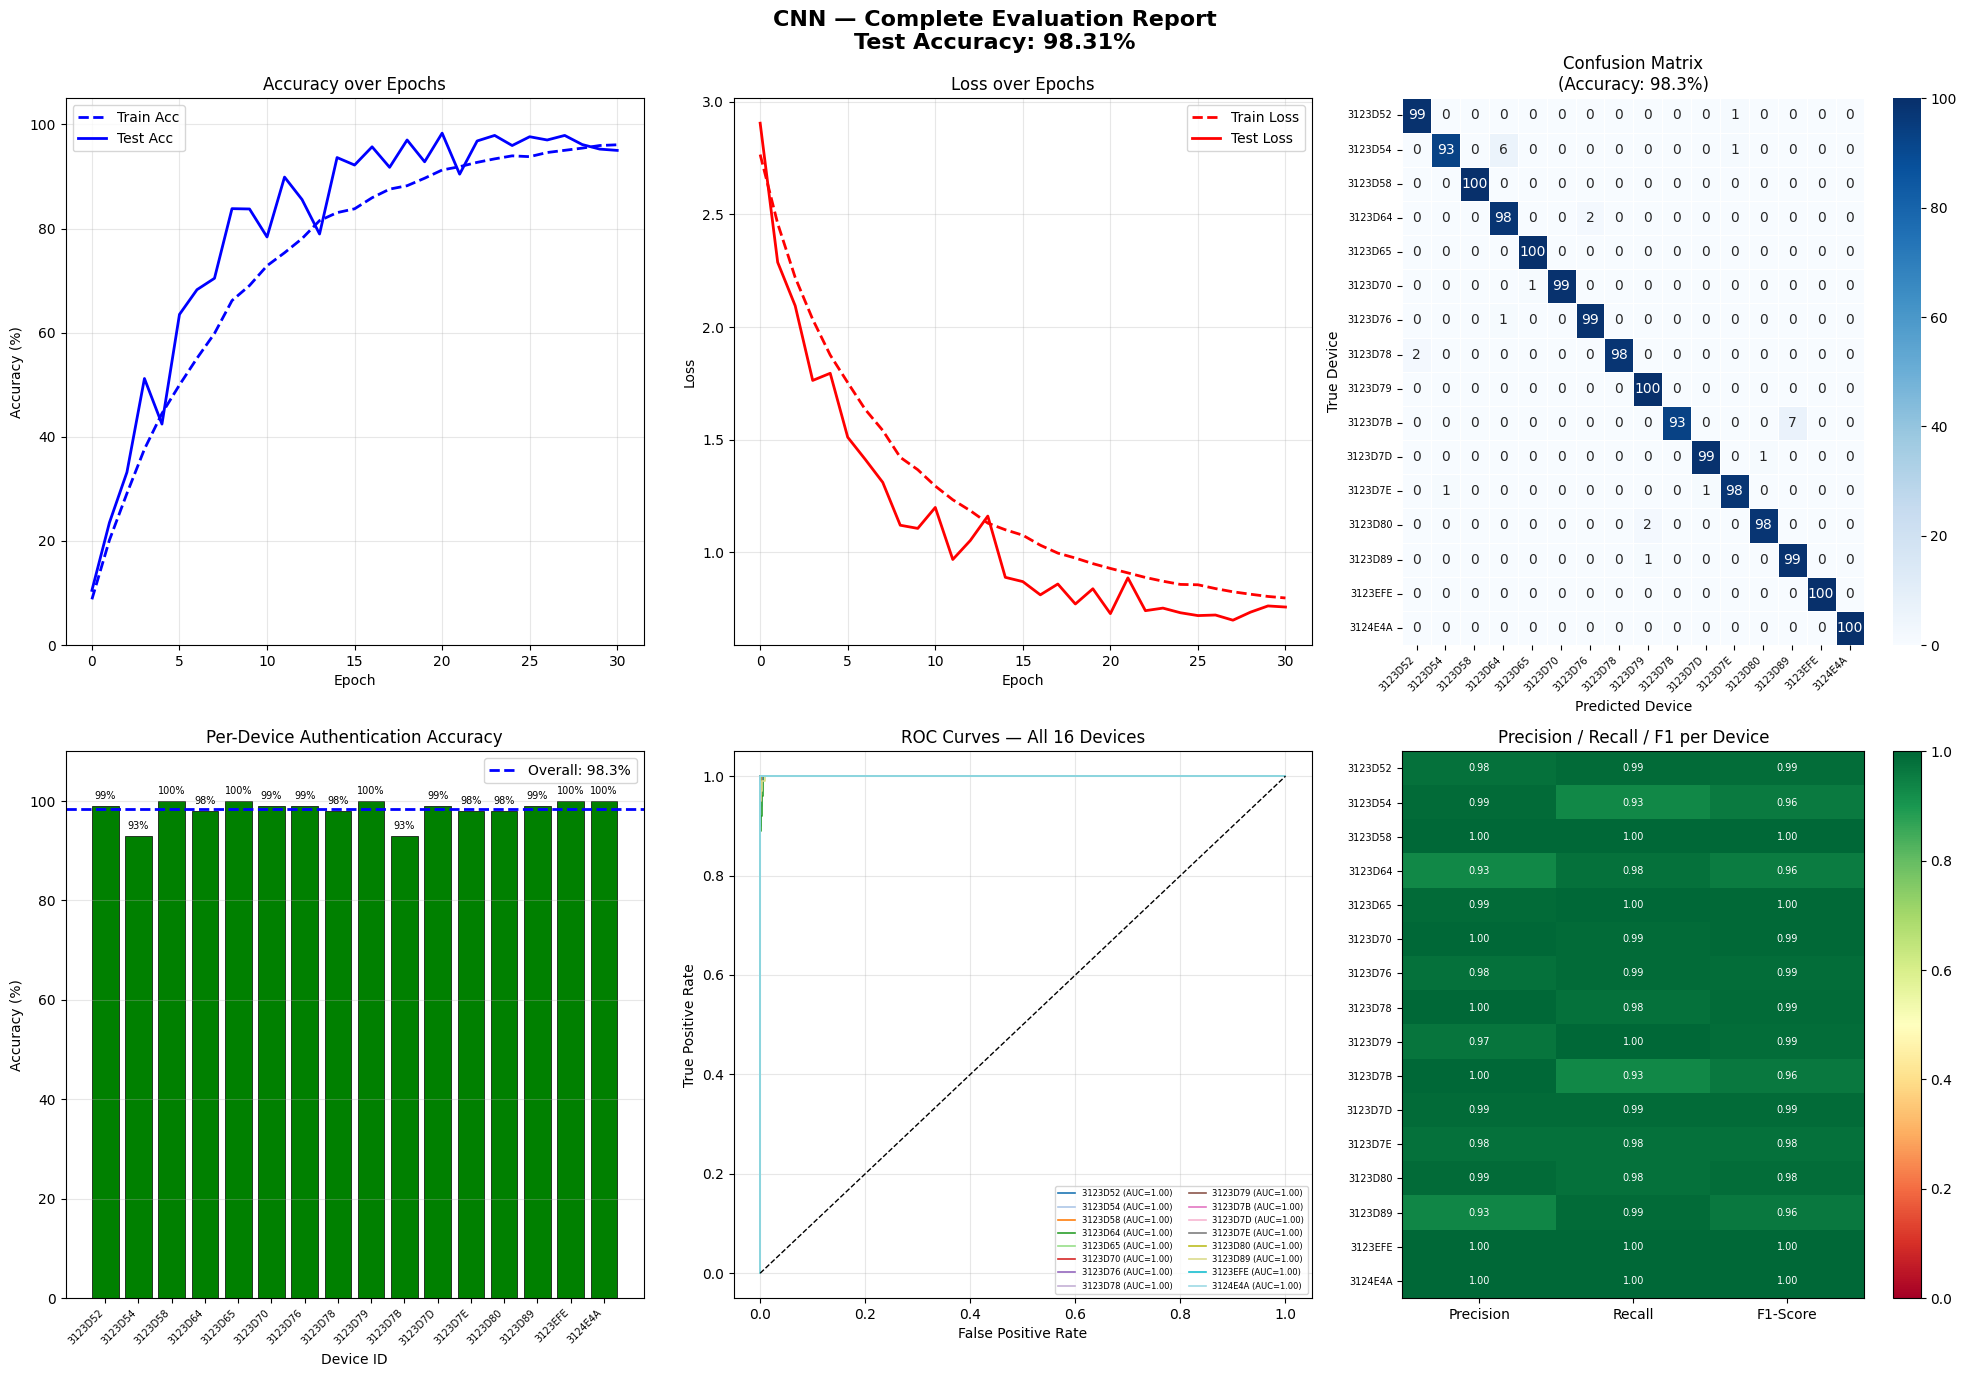


CNN Classification Report:
              precision    recall  f1-score   support

     3123D52       0.98      0.99      0.99       100
     3123D54       0.99      0.93      0.96       100
     3123D58       1.00      1.00      1.00       100
     3123D64       0.93      0.98      0.96       100
     3123D65       0.99      1.00      1.00       100
     3123D70       1.00      0.99      0.99       100
     3123D76       0.98      0.99      0.99       100
     3123D78       1.00      0.98      0.99       100
     3123D79       0.97      1.00      0.99       100
     3123D7B       1.00      0.93      0.96       100
     3123D7D       0.99      0.99      0.99       100
     3123D7E       0.98      0.98      0.98       100
     3123D80       0.99      0.98      0.98       100
     3123D89       0.93      0.99      0.96       100
     3123EFE       1.00      1.00      1.00       100
     3124E4A       1.00      1.00      1.00       100

    accuracy                           0.98      160

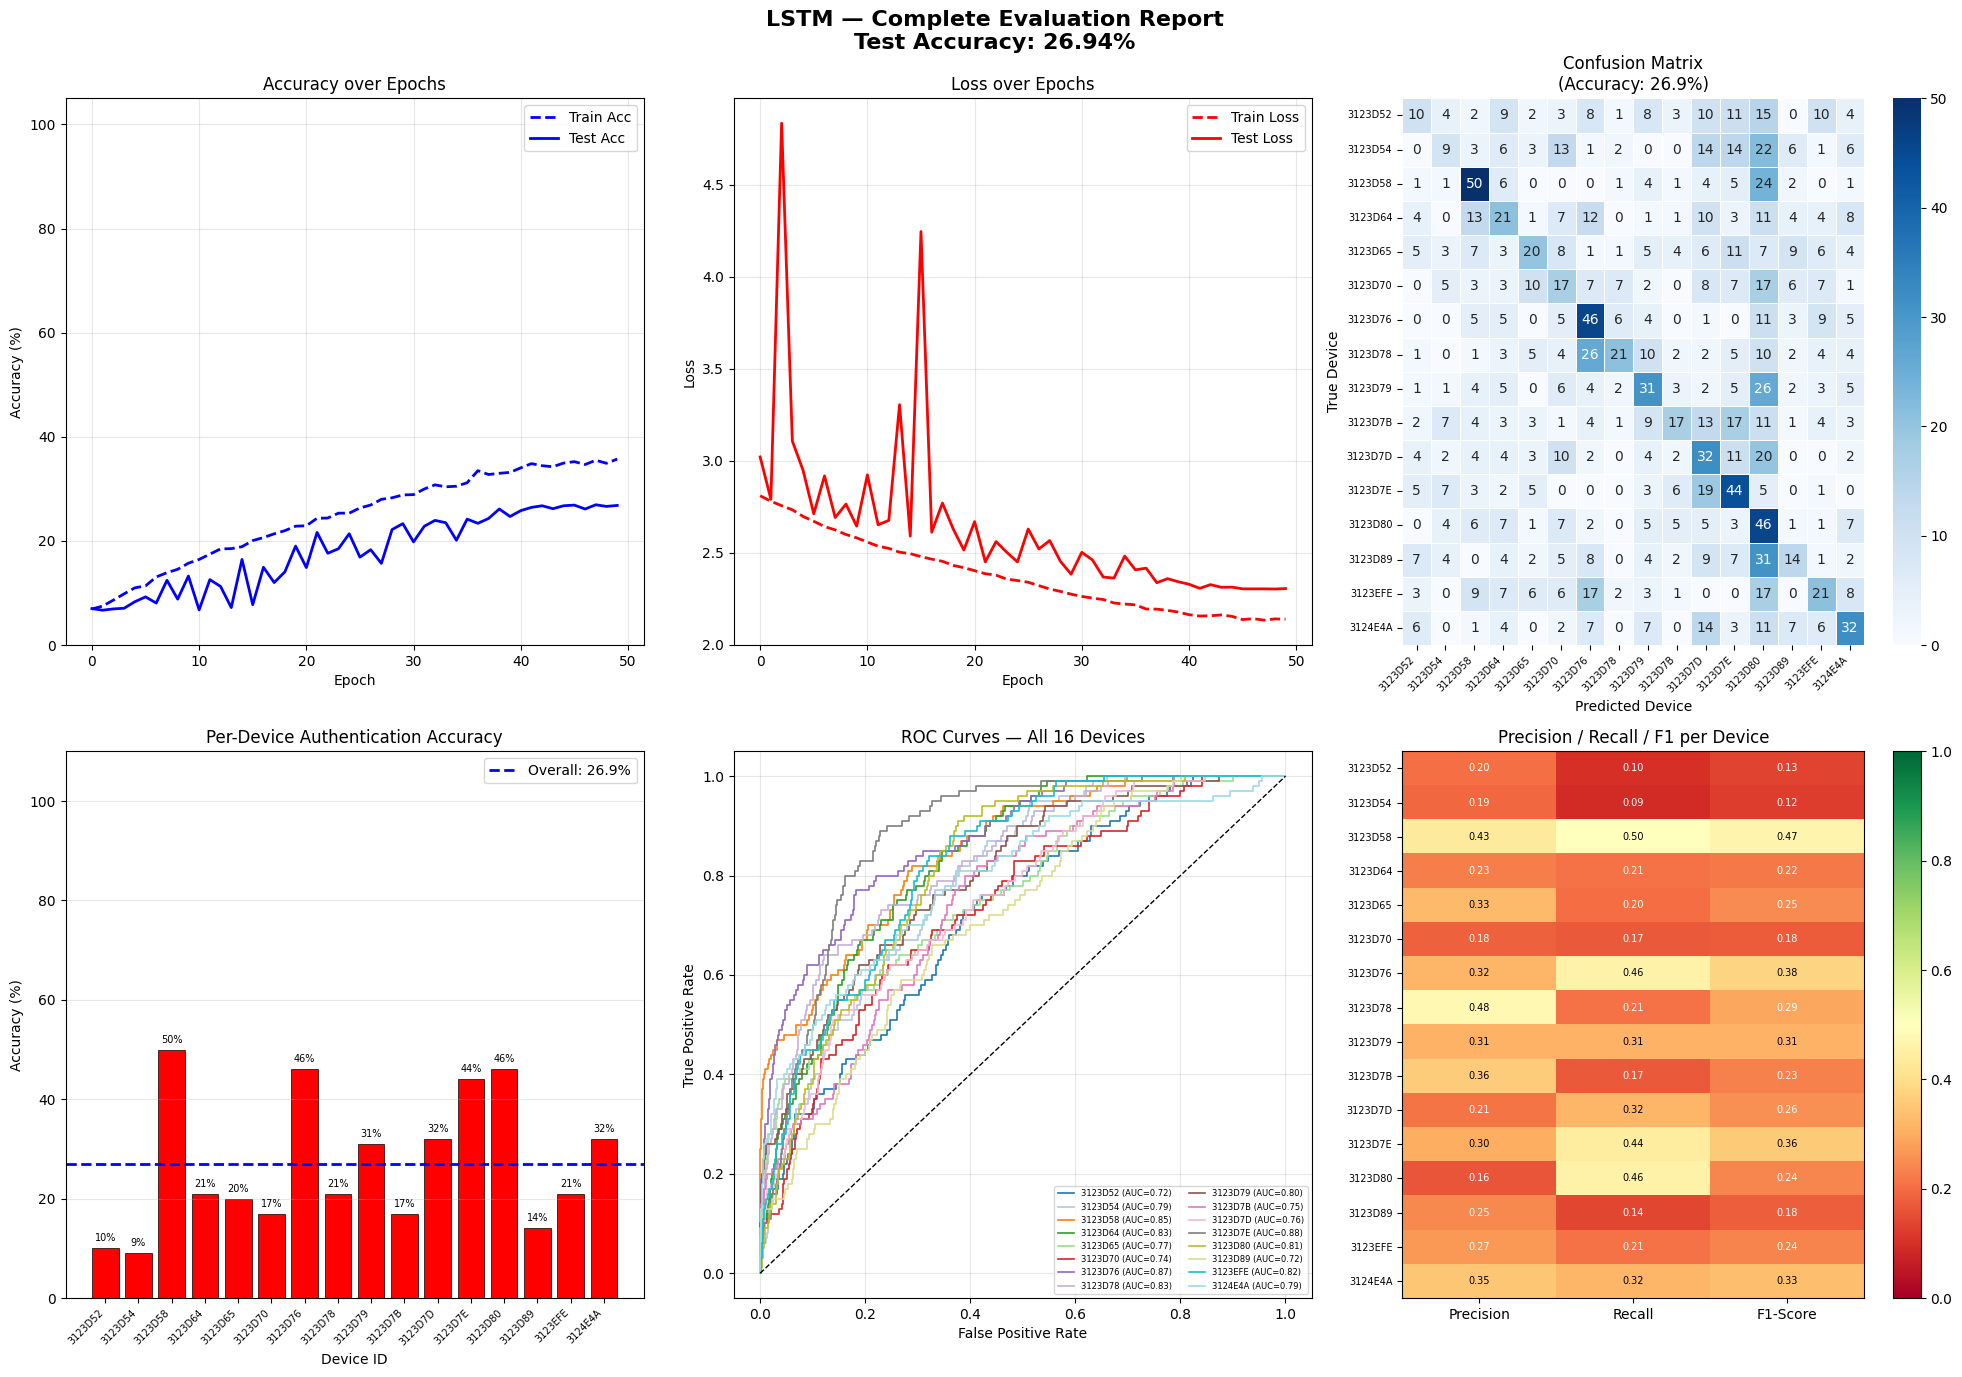


LSTM Classification Report:
              precision    recall  f1-score   support

     3123D52       0.20      0.10      0.13       100
     3123D54       0.19      0.09      0.12       100
     3123D58       0.43      0.50      0.47       100
     3123D64       0.23      0.21      0.22       100
     3123D65       0.33      0.20      0.25       100
     3123D70       0.18      0.17      0.18       100
     3123D76       0.32      0.46      0.38       100
     3123D78       0.48      0.21      0.29       100
     3123D79       0.31      0.31      0.31       100
     3123D7B       0.36      0.17      0.23       100
     3123D7D       0.21      0.32      0.26       100
     3123D7E       0.30      0.44      0.36       100
     3123D80       0.16      0.46      0.24       100
     3123D89       0.25      0.14      0.18       100
     3123EFE       0.27      0.21      0.24       100
     3124E4A       0.35      0.32      0.33       100

    accuracy                           0.27      16

In [ ]:
def full_evaluation(model, test_loader, device_ids,
                    model_name, history):
    """Generate all evaluation plots for paper."""
    model.eval()
    all_preds, all_labels, all_probs = [], [], []

    with torch.no_grad():
        for Xb, yb in test_loader:
            out  = model(Xb.to(device))
            prob = torch.softmax(out, dim=1)
            _, pred = torch.max(out, 1)
            all_preds.extend(pred.cpu().numpy())
            all_labels.extend(yb.numpy())
            all_probs.extend(prob.cpu().numpy())

    all_preds  = np.array(all_preds)
    all_labels = np.array(all_labels)
    all_probs  = np.array(all_probs)

    acc = 100 * np.mean(all_preds == all_labels)

    fig = plt.figure(figsize=(20, 14))
    fig.suptitle(f'{model_name} — Complete Evaluation Report\n'
                 f'Test Accuracy: {acc:.2f}%', fontsize=16, fontweight='bold')

    # ── Plot 1: Training curves ───────────────────────────────────────────────
    ax1 = fig.add_subplot(2, 3, 1)
    ax1.plot(history['train_acc'], 'b--', label='Train Acc', linewidth=2)
    ax1.plot(history['test_acc'],  'b-',  label='Test Acc',  linewidth=2)
    ax1.set_title('Accuracy over Epochs')
    ax1.set_xlabel('Epoch'); ax1.set_ylabel('Accuracy (%)')
    ax1.legend(); ax1.grid(True, alpha=0.3)
    ax1.set_ylim(0, 105)

    # ── Plot 2: Loss curves ───────────────────────────────────────────────────
    ax2 = fig.add_subplot(2, 3, 2)
    ax2.plot(history['train_loss'], 'r--', label='Train Loss', linewidth=2)
    ax2.plot(history['test_loss'],  'r-',  label='Test Loss',  linewidth=2)
    ax2.set_title('Loss over Epochs')
    ax2.set_xlabel('Epoch'); ax2.set_ylabel('Loss')
    ax2.legend(); ax2.grid(True, alpha=0.3)

    # ── Plot 3: Confusion matrix ──────────────────────────────────────────────
    ax3 = fig.add_subplot(2, 3, 3)
    cm  = confusion_matrix(all_labels, all_preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=device_ids, yticklabels=device_ids,
                ax=ax3, linewidths=0.5)
    ax3.set_title(f'Confusion Matrix\n(Accuracy: {acc:.1f}%)')
    ax3.set_ylabel('True Device')
    ax3.set_xlabel('Predicted Device')
    plt.setp(ax3.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    plt.setp(ax3.get_yticklabels(), rotation=0, fontsize=7)

    # ── Plot 4: Per-class accuracy bar chart ─────────────────────────────────
    ax4 = fig.add_subplot(2, 3, 4)
    per_class_acc = []
    for i in range(len(device_ids)):
        mask = all_labels == i
        if mask.sum() > 0:
            per_class_acc.append(100 * (all_preds[mask] == i).mean())
        else:
            per_class_acc.append(0)
    colors = ['green' if a >= 80 else 'orange' if a >= 60 else 'red'
              for a in per_class_acc]
    bars = ax4.bar(device_ids, per_class_acc, color=colors, edgecolor='black', linewidth=0.5)
    ax4.axhline(y=acc, color='blue', linestyle='--',
                linewidth=2, label=f'Overall: {acc:.1f}%')
    ax4.set_title('Per-Device Authentication Accuracy')
    ax4.set_xlabel('Device ID')
    ax4.set_ylabel('Accuracy (%)')
    ax4.set_ylim(0, 110)
    ax4.legend()
    ax4.grid(True, alpha=0.3, axis='y')
    plt.setp(ax4.get_xticklabels(), rotation=45, ha='right', fontsize=7)
    for bar, val in zip(bars, per_class_acc):
        ax4.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1,
                 f'{val:.0f}%', ha='center', va='bottom', fontsize=7)

    # ── Plot 5: ROC curves ────────────────────────────────────────────────────
    from sklearn.metrics import roc_curve, auc
    from sklearn.preprocessing import label_binarize
    ax5 = fig.add_subplot(2, 3, 5)
    y_bin = label_binarize(all_labels, classes=list(range(len(device_ids))))
    colors_roc = plt.cm.tab20(np.linspace(0, 1, len(device_ids)))
    for i, (dev, col) in enumerate(zip(device_ids, colors_roc)):
        fpr, tpr, _ = roc_curve(y_bin[:, i], all_probs[:, i])
        roc_auc     = auc(fpr, tpr)
        ax5.plot(fpr, tpr, color=col, lw=1.2,
                 label=f'{dev} (AUC={roc_auc:.2f})')
    ax5.plot([0,1],[0,1],'k--', lw=1)
    ax5.set_title('ROC Curves — All 16 Devices')
    ax5.set_xlabel('False Positive Rate')
    ax5.set_ylabel('True Positive Rate')
    ax5.legend(loc='lower right', fontsize=6, ncol=2)
    ax5.grid(True, alpha=0.3)

    # ── Plot 6: Classification report heatmap ─────────────────────────────────
    ax6 = fig.add_subplot(2, 3, 6)
    report = classification_report(all_labels, all_preds,
                                   target_names=device_ids,
                                   output_dict=True)
    metrics_df = np.array([[report[d]['precision'],
                            report[d]['recall'],
                            report[d]['f1-score']]
                           for d in device_ids])
    im = ax6.imshow(metrics_df, aspect='auto', cmap='RdYlGn', vmin=0, vmax=1)
    ax6.set_xticks([0,1,2])
    ax6.set_xticklabels(['Precision','Recall','F1-Score'])
    ax6.set_yticks(range(len(device_ids)))
    ax6.set_yticklabels(device_ids, fontsize=7)
    ax6.set_title('Precision / Recall / F1 per Device')
    plt.colorbar(im, ax=ax6)
    for i in range(len(device_ids)):
        for j, val in enumerate(metrics_df[i]):
            ax6.text(j, i, f'{val:.2f}', ha='center', va='center',
                     fontsize=7,
                     color='black' if 0.3 < val < 0.8 else 'white')

    plt.tight_layout()
    plt.savefig(f'/content/drive/MyDrive/RF_Project/{model_name}_evaluation.png',
                dpi=150, bbox_inches='tight')
    plt.show()

    # Print classification report
    print(f"\n{model_name} Classification Report:")
    print(classification_report(all_labels, all_preds,
                                target_names=device_ids))

    return acc, all_preds, all_labels, all_probs

# ── Evaluate both models ───────────────────────────────────────────────────────
print("\nEvaluating CNN...")
cnn_acc, cnn_preds, cnn_labels, cnn_probs = full_evaluation(
    cnn_model, test_loader_cnn, device_ids, 'CNN', cnn_history)

print("\nEvaluating LSTM...")
lstm_acc, lstm_preds, lstm_labels, lstm_probs = full_evaluation(
    lstm_model, test_loader_lstm, device_ids, 'LSTM', lstm_history)

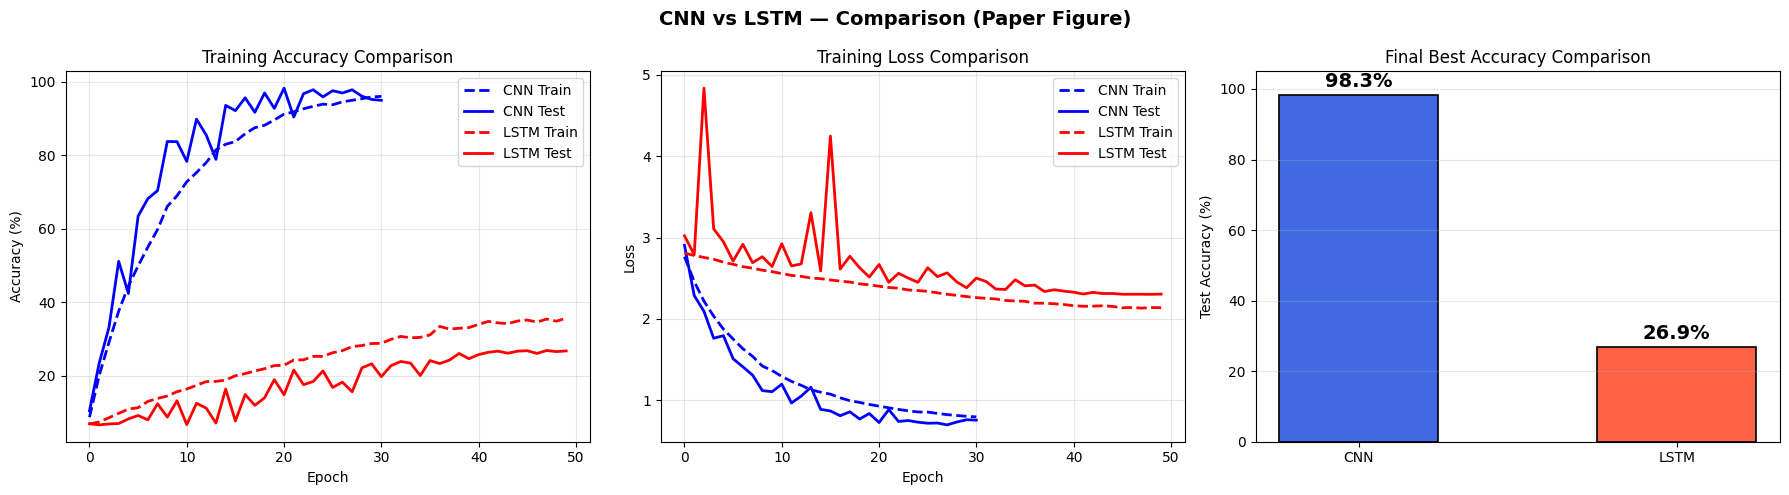


FINAL RESULTS SUMMARY
CNN  Best Accuracy: 98.31%
LSTM Best Accuracy: 26.94%
Dataset: 8000 total samples from 5 distances
Devices: 16 USRP X310 devices


In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('CNN vs LSTM — Comparison (Paper Figure)', fontsize=14, fontweight='bold')

# Accuracy
axes[0].plot(cnn_history['train_acc'],  'b--', label='CNN Train',  lw=2)
axes[0].plot(cnn_history['test_acc'],   'b-',  label='CNN Test',   lw=2)
axes[0].plot(lstm_history['train_acc'], 'r--', label='LSTM Train', lw=2)
axes[0].plot(lstm_history['test_acc'],  'r-',  label='LSTM Test',  lw=2)
axes[0].set_title('Training Accuracy Comparison')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy (%)')
axes[0].legend(); axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(cnn_history['train_loss'],  'b--', label='CNN Train',  lw=2)
axes[1].plot(cnn_history['test_loss'],   'b-',  label='CNN Test',   lw=2)
axes[1].plot(lstm_history['train_loss'], 'r--', label='LSTM Train', lw=2)
axes[1].plot(lstm_history['test_loss'],  'r-',  label='LSTM Test',  lw=2)
axes[1].set_title('Training Loss Comparison')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(True, alpha=0.3)

# Final accuracy bar
axes[2].bar(['CNN', 'LSTM'],
            [cnn_best_acc, lstm_best_acc],
            color=['royalblue', 'tomato'],
            edgecolor='black', linewidth=1.2, width=0.5)
axes[2].set_title('Final Best Accuracy Comparison')
axes[2].set_ylabel('Test Accuracy (%)')
axes[2].set_ylim(0, 105)
axes[2].grid(True, alpha=0.3, axis='y')
for i, (name, val) in enumerate([('CNN', cnn_best_acc), ('LSTM', lstm_best_acc)]):
    axes[2].text(i, val + 1, f'{val:.1f}%',
                 ha='center', va='bottom', fontsize=14, fontweight='bold')

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/RF_Project/CNN_vs_LSTM_comparison.png',
            dpi=150, bbox_inches='tight')
plt.show()

print(f"\n{'='*50}")
print(f"FINAL RESULTS SUMMARY")
print(f"{'='*50}")
print(f"CNN  Best Accuracy: {cnn_best_acc:.2f}%")
print(f"LSTM Best Accuracy: {lstm_best_acc:.2f}%")
print(f"Dataset: {len(y_all)} total samples from {len(TRAIN_DISTANCES)} distances")
print(f"Devices: {NUM_CLASSES} USRP X310 devices")
print(f"{'='*50}")